# Redes nueronales (cuerpo del proyecto)

## Set up

In [3]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_config
from src.runtime import limit_threads
cfg = load_config()
N_THREADS = limit_threads(cfg)                      # ANTES de usar Keras

import keras
from src.preprocessing import load_split
from src.models import build_model
from src.train import make_inputs, train_model

SEED = cfg["seeds"][0]
tr, dv = load_split(cfg, "train"), load_split(cfg, "dev")
X_tr, idx_tr, y_tr = tr["X"], tr["idx"], tr["y"]["isFraud"]
X_dv, idx_dv, y_dv = dv["X"], dv["idx"], dv["y"]["isFraud"]



## Exploración básica de funcionamiento

### Prueba de humo para el entrenamiento

In [4]:
meta = json.load(open(ROOT / cfg["paths"]["models_dir"] / "preprocessor_meta.json"))
vocab, idx_cols = meta["vocab_sizes"], list(meta["vocab_sizes"])
idx_tr, idx_dv = idx_tr[idx_cols], idx_dv[idx_cols]
for c, v in vocab.items():                          # ningún índice fuera del vocabulario
    assert 0 <= idx_tr[c].min() and idx_tr[c].max() < v and idx_dv[c].max() < v, c
print("entradas OK:", X_tr.shape, len(idx_cols), "columnas idx")

for kind, strat in [("mlp", "class_weight"), ("mlp_regularizado", "class_weight"),
                    ("mlp_embeddings", "class_weight"), ("residual_mlp", "class_weight"),
                    ("mlp", "focal")]:
    keras.backend.clear_session()
    model = build_model(kind, cfg, X_tr.shape[1], vocab)
    tr_in = make_inputs(X_tr, idx_tr, kind, idx_cols)
    dv_in = make_inputs(X_dv, idx_dv, kind, idx_cols)
    out = train_model(model, (tr_in, y_tr), (dv_in, y_dv), cfg, strat, SEED, kind=kind,
                      variant="smoke", n_features=X_tr.shape[1], max_epochs=3,
                      log=False, save_weights=False)
    h = out["history"]["val_pr_auc"]
    print(f"{kind:<18} {strat:<13} {model.count_params():>9,} params | "
          f"val_pr_auc por época {np.round(h, 3)} | {out['train_time_s']/len(h):.1f} s/época")

entradas OK: (413378, 383) 13 columnas idx
mlp                class_weight    131,329 params | val_pr_auc por época [0.452 0.464 0.47 ] | 1.3 s/época
mlp_regularizado   class_weight    132,481 params | val_pr_auc por época [0.436 0.46  0.467] | 2.0 s/época
mlp_embeddings     class_weight    255,330 params | val_pr_auc por época [0.466 0.484 0.494] | 3.3 s/época
residual_mlp       class_weight    498,689 params | val_pr_auc por época [0.41  0.446 0.468] | 5.8 s/época
mlp                focal           131,329 params | val_pr_auc por época [0.436 0.464 0.476] | 1.3 s/época


### Resumen ejecutivo de las NN

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
RESUMEN COMPARATIVO


,Arquitectura,Entradas,Dense,BatchNorm,Dropout,Embedding,Add (residual),Entrenables,No entrenables (BN),Total,MB (float32)
0,1. MLP convencional,1,3,0,0,0,0,131329,0,131329,0.53
1,2. MLP regularizada,1,3,2,2,0,0,131713,768,132481,0.53
2,3. MLP con embeddings,14,3,2,2,13,0,254562,768,255330,1.02
3,4. Residual MLP,1,8,7,3,0,3,495105,3584,498689,1.99



HIPERPARÁMETROS DE LA CONFIGURACIÓN


... (10 outputs left out)

,#,Capa,Tipo,Salida,Parámetros,Detalle
0,0,card1_idx,InputLayer,"(1,)",0,
1,1,card2_idx,InputLayer,"(1,)",0,
2,2,card3_idx,InputLayer,"(1,)",0,
3,3,card5_idx,InputLayer,"(1,)",0,
4,4,addr1_idx,InputLayer,"(1,)",0,
5,5,addr2_idx,InputLayer,"(1,)",0,
6,6,P_emaildomain_idx,InputLayer,"(1,)",0,
7,7,R_emaildomain_idx,InputLayer,"(1,)",0,
8,8,id_30_idx,InputLayer,"(1,)",0,
9,9,id_31_idx,InputLayer,"(1,)",0,


Model: "mlp_embeddings"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ card1_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ card2_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ card3_idx (InputLayer)            │ (None, 1)                    │                 0 │ -                         
├───────────────────────────────────┼───────────

,#,Capa,Tipo,Salida,Parámetros,Detalle
0,0,x,InputLayer,"(383,)",0,
1,1,dense,Dense,"(256,)",98048,"unidades=256, activación=linear, sesgo=False, ..."
2,2,batch_normalization,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"
3,3,activation,Activation,"(256,)",0,activación=relu
4,4,dense_1,Dense,"(256,)",65536,"unidades=256, activación=linear, sesgo=False, ..."
5,5,batch_normalization_1,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"
6,6,activation_1,Activation,"(256,)",0,activación=relu
7,7,dropout,Dropout,"(256,)",0,tasa=0.2
8,8,dense_2,Dense,"(256,)",65536,"unidades=256, activación=linear, sesgo=False, ..."
9,9,batch_normalization_2,BatchNormalization,"(256,)",1024,"momentum=0.99, épsilon=0.001"


Model: "residual_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━
┃ Layer (type)                      ┃ Output Shape                 ┃           Param # ┃ Connected to              
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━
│ x (InputLayer)                    │ (None, 383)                  │                 0 │ -                         
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ dense (Dense)                     │ (None, 256)                  │            98,048 │ x[0][0]                   
├───────────────────────────────────┼──────────────────────────────┼───────────────────┼───────────────────────────
│ batch_normalization               │ (None, 256)                  │             1,024 │ dense[0][0]               
│ (BatchNormalization)              │             

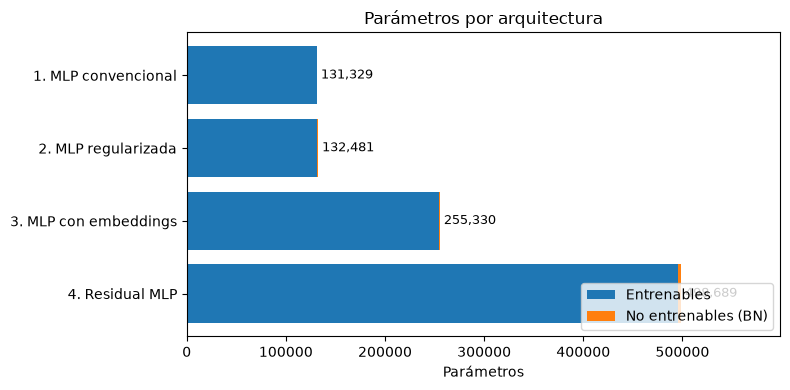


Guardado: reports\nn_architectures.md | CSV por arquitectura en reports/ | figura 23_nn_parameters.png


In [2]:
# ============================================================
# Documentación de las arquitecturas (parámetros e información de las redes)
# ===========================================================

import io
import keras
from collections import Counter
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from src.train import compute_class_weights



KINDS = ["mlp", "mlp_regularizado", "mlp_embeddings", "residual_mlp"]
NOMBRES = {"mlp": "1. MLP convencional", "mlp_regularizado": "2. MLP regularizada",
           "mlp_embeddings": "3. MLP con embeddings", "residual_mlp": "4. Residual MLP"}
OVERRIDES = {}     # tras la Acción 8: {"mlp_regularizado": {"hidden": [512, 256], "dropout": 0.2}, ...}
HACER_DIAGRAMAS = True   # requiere pydot + Graphviz; si faltan, se omite sin error

FIG_DIR = ROOT / cfg["paths"]["figures_dir"]
OUT_MD = ROOT / "reports" / "nn_architectures.md"
OUT_MD.parent.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _clase(x):
    return x.get("class_name", "") if isinstance(x, dict) else (x or "")

def _l2(x):
    if isinstance(x, dict) and str(x.get("class_name", "")).lower() == "l2":
        return x["config"].get("l2")
    return None

def forma(layer):
    try:
        return str(tuple(layer.output.shape[1:]))
    except Exception:
        return "?"

def detalle(layer):
    c, t = layer.get_config(), layer.__class__.__name__
    if t == "Dense":
        s = (f"unidades={c['units']}, activación={c['activation']}, sesgo={c['use_bias']}, "
             f"inicialización={_clase(c['kernel_initializer'])}")
        l2 = _l2(c.get("kernel_regularizer"))
        return s + (f", L2={l2:g}" if l2 else "")
    if t == "BatchNormalization":
        return f"momentum={c['momentum']}, épsilon={c['epsilon']}"
    if t == "Dropout":
        return f"tasa={c['rate']}"
    if t == "Embedding":
        s = f"vocabulario={c['input_dim']}, dimensión={c['output_dim']}"
        l2 = _l2(c.get("embeddings_regularizer"))
        return s + (f", L2={l2:g}" if l2 else "")
    if t == "Activation":
        return f"activación={c['activation']}"
    return ""

def md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(str(v).replace("|", "\\|") for v in r) + " |")
    return "\n".join(out)


resumen, capas, resumenes_keras, emb_tabla, hp_rows = [], {}, {}, None, []
for kind in KINDS:
    keras.backend.clear_session()
    m = build_model(kind, cfg, X_tr.shape[1], vocab, **OVERRIDES.get(kind, {}))

    # parámetros
    n_tr = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    n_nt = int(sum(np.prod(w.shape) for w in m.non_trainable_weights))
    cnt = Counter(l.__class__.__name__ for l in m.layers)
    hp = {**cfg["nn"]["architectures"][kind], **OVERRIDES.get(kind, {})}
    resumen.append({
        "Arquitectura": NOMBRES[kind], "Entradas": len(m.inputs),
        "Dense": cnt["Dense"], "BatchNorm": cnt["BatchNormalization"], "Dropout": cnt["Dropout"],
        "Embedding": cnt["Embedding"], "Add (residual)": cnt["Add"],
        "Entrenables": n_tr, "No entrenables (BN)": n_nt, "Total": n_tr + n_nt,
        "MB (float32)": round((n_tr + n_nt) * 4 / 1e6, 2),
    })
    hp_rows.append({"Arquitectura": NOMBRES[kind], "Hiperparámetros": json.dumps(hp)})

    # capa por capa
    capas[kind] = pd.DataFrame([{
        "#": i, "Capa": l.name, "Tipo": l.__class__.__name__, "Salida": forma(l),
        "Parámetros": l.count_params(), "Detalle": detalle(l)} for i, l in enumerate(m.layers)])
    capas[kind].to_csv(ROOT / "reports" / f"nn_layers_{kind}.csv", index=False)

    # summary de Keras como texto
    lineas = []
    m.summary(print_fn=lambda s, **k: lineas.append(str(s)), line_length=120)
    resumenes_keras[kind] = "\n".join(lineas)

    # tabla de embeddings
    if kind == "mlp_embeddings":
        filas = []
        for l in m.layers:
            if l.__class__.__name__ == "Embedding":
                c = l.get_config()
                filas.append({"Variable": l.name.replace("emb_", ""), "Vocabulario": c["input_dim"],
                              "Dimensión": c["output_dim"], "Parámetros": l.count_params()})
        emb_tabla = pd.DataFrame(filas)
        emb_tabla["% de los parámetros de embeddings"] = (100 * emb_tabla["Parámetros"]
                                                          / emb_tabla["Parámetros"].sum()).round(1)

    if HACER_DIAGRAMAS:
        try:
            keras.utils.plot_model(m, to_file=str(FIG_DIR / f"arch_{kind}.png"),
                                   show_shapes=True, show_layer_names=True, dpi=110)
        except Exception as e:
            HACER_DIAGRAMAS = False
            print("Diagramas omitidos (requieren pydot y Graphviz):", type(e).__name__)

resumen_df, hp_df = pd.DataFrame(resumen), pd.DataFrame(hp_rows)

# protocolo de entrenamiento
w = compute_class_weights(y_tr, cfg["imbalance"]["class_weight_mode"])
nn_c, imb = cfg["nn"]["common"], cfg["imbalance"]
protocolo = pd.DataFrame([
    ("Datos de entrada", f"X: {X_tr.shape[1]} columnas; idx: {len(vocab)} columnas de índices (solo la MLP con embeddings)"),
    ("Filas", f"train {len(X_tr):,} | dev {len(X_dv):,} (el test no se usa en esta etapa)"),
    ("Optimizador", f"Adam, tasa de aprendizaje {nn_c['learning_rate']}"),
    ("Tamaño de lote / épocas máximas", f"{nn_c['batch_size']} / {nn_c['max_epochs']}"),
    ("Early stopping", f"PR-AUC exacto en dev, paciencia {nn_c['early_stopping_patience']}, restore_best_weights=True"),
    ("Inicialización", "He normal en las capas Dense; Embedding con la inicialización por defecto de Keras"),
    ("Estrategia class_weight", f"entropía cruzada binaria con pesos de train {w['class_weight'][0]:.3f} / "
                                f"{w['class_weight'][1]:.3f}; sesgo de salida inicial 0"),
    ("Estrategia focal", f"BinaryFocalCrossentropy (gamma={imb['focal_gamma']}, alpha={imb['focal_alpha']}), sin pesos "
                         f"de clase; sesgo de salida inicial log(n1/n0) = {np.log(w['n1'] / w['n0']):.3f}"),
    ("Costo asumido", f"c_FN={cfg['cost']['c_FN']}, c_FP={cfg['cost']['c_FP']}, precisión objetivo {cfg['cost']['target_precision']}"),
    ("Semillas", f"{cfg['seeds']} (búsqueda con {cfg['seeds'][0]})"),
    ("Entorno", f"TensorFlow {tf.__version__}, Keras {keras.__version__}, {N_THREADS} hilos de CPU"),
], columns=["Elemento", "Valor"])

# ---- mostrar en el notebook ----
print("RESUMEN COMPARATIVO"); display(resumen_df)
print("\nHIPERPARÁMETROS DE LA CONFIGURACIÓN"); display(hp_df)
print("\nPROTOCOLO DE ENTRENAMIENTO"); display(protocolo)
print("\nEMBEDDINGS (MLP con embeddings)"); display(emb_tabla)
for kind in KINDS:
    print(f"\n{'=' * 100}\n{NOMBRES[kind]}\n{'=' * 100}")
    display(capas[kind])
    print(resumenes_keras[kind])

# ---- figura: parámetros por arquitectura ----
fig, ax = plt.subplots(figsize=(8, 4))
nombres = [NOMBRES[k] for k in KINDS]
ax.barh(nombres, resumen_df["Entrenables"], label="Entrenables")
ax.barh(nombres, resumen_df["No entrenables (BN)"], left=resumen_df["Entrenables"], label="No entrenables (BN)")
for i, t in enumerate(resumen_df["Total"]):
    ax.text(t, i, f" {t:,}", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Parámetros"); ax.set_title("Parámetros por arquitectura")
ax.legend(loc="lower right"); ax.set_xlim(0, resumen_df["Total"].max() * 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "23_nn_parameters.png", dpi=150); plt.show()

# ---- exportar a Markdown (README / model card) ----
partes = ["# Arquitecturas de red\n",
          "Valores de `configs/default.yaml` (más `OVERRIDES` si se usaron). Generado desde `04_neural_networks.ipynb`.\n",
          "## Resumen comparativo\n", md(resumen_df), "\n## Hiperparámetros\n", md(hp_df),
          "\n## Protocolo de entrenamiento\n", md(protocolo), "\n## Embeddings\n", md(emb_tabla)]
for kind in KINDS:
    partes += [f"\n## {NOMBRES[kind]}\n", md(capas[kind]), "\n```text\n" + resumenes_keras[kind] + "\n```"]
OUT_MD.write_text("\n".join(partes), encoding="utf-8")
print("\nGuardado:", OUT_MD.relative_to(ROOT), "| CSV por arquitectura en reports/ | figura 23_nn_parameters.png")